# M9: Load-based cascade model

**Paper section covered:** none (Part B, work beyond the paper). Extension E5; the realistic counterpart of the threshold cascade of M6.

## The gap
The paper's cascade (Section 5.2, reproduced in M6) is **purely topological**: an airport fails when a fraction of its *neighbours* has failed. Real airports do not fail because their neighbours failed; they fail because they are **overloaded**. When an airport closes, its traffic is re-routed through other airports, which then carry more than they were built for, and some of them fail in turn. This is the mechanism of the 2003 North-American blackout that the paper's own introduction reminds us of, and the standard model for it is the **Motter-Lai load-capacity cascade** (2002).

## The model
1. **Load.** Every pair of airports exchanges traffic along shortest paths (split equally between equally short paths). The load of an airport is the traffic that passes through it, *including* traffic that starts or ends there. With one unit of traffic per pair, this is the airport's betweenness plus (N - 1), so **the paper's betweenness is exactly the load of this model**.
2. **Capacity.** Each airport can handle (1 + alpha) times its initial load; alpha is the spare capacity ("tolerance parameter").
3. **Cascade.** Remove one airport (the origin). Traffic re-routes on what is left, loads are recomputed, every airport whose load now exceeds its capacity fails, and the process repeats until nothing new fails.

The key quantity is **alpha_c**: the largest spare capacity at which a given origin's failure still destroys most of the network (final largest component at most half of the airports, as in M5 and M6). The smallest spare capacity that makes the whole network safe against any single failure is the maximum of alpha_c over all origins.

## Goals
1. Implement and validate the model; study one cascade in detail.
2. Run the cascade from **every airport** and every alpha: which airports are dangerous, and how much spare capacity does the network need?
3. **Compare with the threshold model of M6:** are the same airports dangerous?
4. Test how much the answers depend on modelling choices (what counts as load, how traffic demand is distributed, how capacity is allocated, whether airports differ in tolerance).
5. Check robustness on the operated-only network of M7, and preview which airports a protection strategy (M11) must reinforce.

## Plan
| Part | Content |
|---|---|
| A | The model: loads, capacities, validation |
| B | One cascade in detail |
| C | Every airport as the origin: the phase diagram |
| D | Comparison with the threshold cascade of M6 |
| E | Sensitivity to modelling choices |
| F | Robustness on the operated-only network |
| G | Which airports overload? (preview for M11) |
| H | Verdict |

## 1. Setup

In [1]:
import sys, warnings, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, weighted as wt, cascade as cs, load_cascade as lc

warnings.filterwarnings("ignore")
pd.set_option("display.width", 175)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE, TEAL, BROWN = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2", "#17a2b8", "#8c564b"

airports, routes = usfn.load_openflights()
G0 = usfn.build_country_network(airports, routes)
G, Gop, cshare = wt.build_weightings(G0, routes)
nodes = list(G.nodes); N = len(nodes)
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in nodes}
deg = dict(G.degree()); strength = dict(G.degree(weight="weight"))
rng = np.random.default_rng(2025)

t0 = time.time()
LC = lc.LoadCascade(G)                                        # baseline: unit demand, load includes the airport's own traffic
print(f"USFN: {N} airports; load engine ready ({time.time() - t0:.1f} s incl. compilation)")

USFN: 541 airports; load engine ready (0.2 s incl. compilation)


## Part A. The model

### A1. Loads, and a check against networkx and a brute-force computation
The load calculation is our own compiled implementation of Brandes' algorithm, extended to give every airport a traffic weight. We check it two ways: against networkx's betweenness on the real network (unit traffic), and against a brute-force enumeration of all shortest paths on a small random graph with *unequal* traffic weights.

max difference to networkx betweenness + (N - 1): 2.2e-11
max difference to brute-force weighted loads on a 25-node test graph: 5.7e-13


airport,load,load / median load,degree,betweenness rank
ANC,48443,89.700000,34,1
DEN,23305,43.200000,149,2
ORD,19332,35.800000,149,3
SEA,18700,34.600000,75,4
ATL,13766,25.500000,153,5
MSP,12935,24.000000,117,6
DFW,12489,23.100000,138,7
BET,12128,22.500000,22,8
FAI,10757,19.900000,18,9
LAS,9799,18.100000,113,10


load: median 540, mean 1134, maximum 48443 (ANC); the smallest load is 540 = N - 1 (an airport that only handles its own traffic)


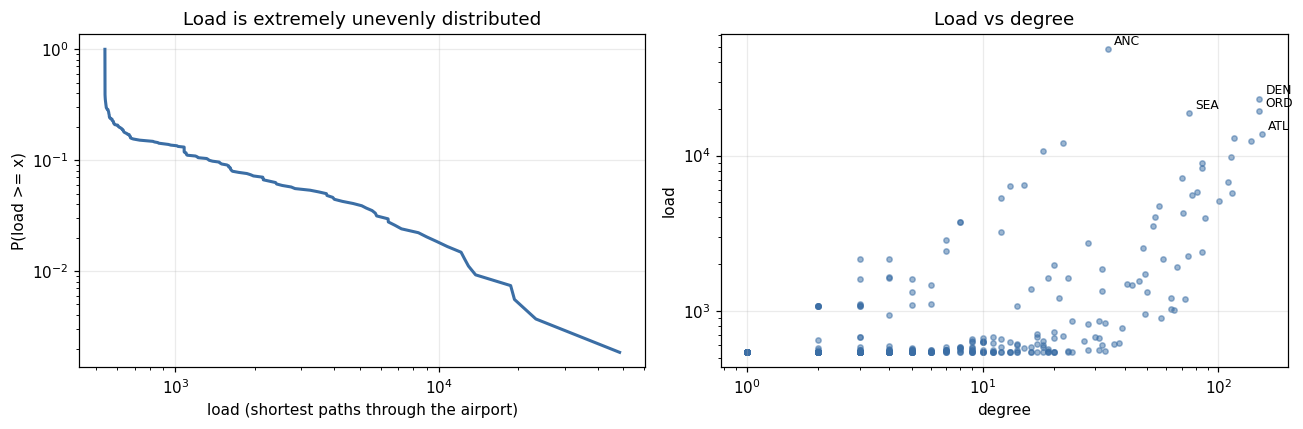

In [2]:
bc = nx.betweenness_centrality(G, normalized=False)
diff_nx = max(abs(LC.L0[LC.idx[n]] / 2 - (bc[n] + N - 1)) for n in nodes)          # ordered pairs / 2 = betweenness + (N - 1) endpoint paths

H = nx.erdos_renyi_graph(25, 0.2, seed=1); H = H.subgraph(max(nx.connected_components(H), key=len)).copy()
dem = {n: 1 + (n % 4) for n in H}
LH = lc.LoadCascade(H, dem); brute = {n: 0.0 for n in H}
for s in H:
    for t in H:
        if s != t:
            paths = list(nx.all_shortest_paths(H, s, t)); f = dem[s] * dem[t] / len(paths)
            for p in paths:
                for v in p: brute[v] += f
diff_brute = max(abs(LH.L0[LH.idx[n]] - brute[n]) for n in H)
print(f"max difference to networkx betweenness + (N - 1): {diff_nx:.1e}")
print(f"max difference to brute-force weighted loads on a {len(H)}-node test graph: {diff_brute:.1e}")

load = pd.Series(LC.L0 / 2, index=nodes)                                         # in unordered-pair units
bc_rank = pd.Series(bc).rank(ascending=False, method="min")
top = pd.DataFrame({"airport": load.sort_values(ascending=False).head(10).index})
top["load"] = [round(load[n]) for n in top.airport]; top["load / median load"] = [round(load[n] / load.median(), 1) for n in top.airport]
top["degree"] = [deg[n] for n in top.airport]; top["betweenness rank"] = [int(bc_rank[n]) for n in top.airport]
display(top.style.hide(axis="index"))
print(f"load: median {load.median():.0f}, mean {load.mean():.0f}, maximum {load.max():.0f} ({load.idxmax()}); the smallest load is {load.min():.0f} = N - 1 (an airport that only handles its own traffic)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.sort(load.values); axes[0].loglog(xs, 1 - np.arange(N) / N, color=BLUE, lw=2); axes[0].set_xlabel("load (shortest paths through the airport)"); axes[0].set_ylabel("P(load >= x)"); axes[0].set_title("Load is extremely unevenly distributed")
axes[1].scatter([deg[n] for n in nodes], load.values, s=12, alpha=0.5, color=BLUE)
for n in ["ANC", "DEN", "ORD", "SEA", "ATL"]: axes[1].annotate(n, (deg[n], load[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("degree"); axes[1].set_ylabel("load"); axes[1].set_title("Load vs degree")
plt.tight_layout(); plt.show()

**Reading this.** The implementation is correct (differences at the level of rounding error). The load is extremely uneven: the busiest airport (ANC, because it is the gateway to Alaska) carries about 90 times the median load; with unit traffic the load ranking is the same as the **betweenness ranking of M1** (ANC, DEN, ORD, SEA, ATL, MSP, DFW, BET). So the paper's headline structural measure is, in the load model, exactly what determines how much an airport has to carry.

The load is also what makes cascades possible: the *capacity* of an airport is set by what it carried before the failure, so a failure makes other airports carry more than 1 + alpha times their normal load only if re-routing concentrates traffic on them.

## Part B. One cascade in detail
Take the failure of **ORD** with 10% spare capacity (alpha = 0.1). The first table shows who is overloaded immediately after ORD's traffic is re-routed, by how much, and the rounds that follow.

airports overloaded right after ORD is removed (load more than 1.1 x normal): 14


airport,load before,load after ORD fails,ratio,degree
AZA,1343,1840,1.37,32
DTW,5733,7068,1.23,114
MSP,12935,15624,1.21,117
PHL,3949,4761,1.21,88
PGD,606,699,1.15,18
PIE,857,983,1.15,31
STL,4723,5395,1.14,56
LAS,9799,11182,1.14,113
SFB,2543,2877,1.13,48
DFW,12489,14080,1.13,138


round,airports failing by overload,examples
1,14,"STL, LAS, MSP, DTW, JFK, PHL, DFW, PHX"
2,15,"ATL, FLL, TPA, MCO, LAX, LGA, CLT, BWI"
3,13,"BOS, MIA, AUS, SAN, SEA, IAD, MKE, MYR"
4,5,"RSW, PBI, CMH, RNO, SJC"


after ORD is removed: largest component 532; after 4 cascade rounds (47 airports overloaded): largest component 131 of 541 (24%)


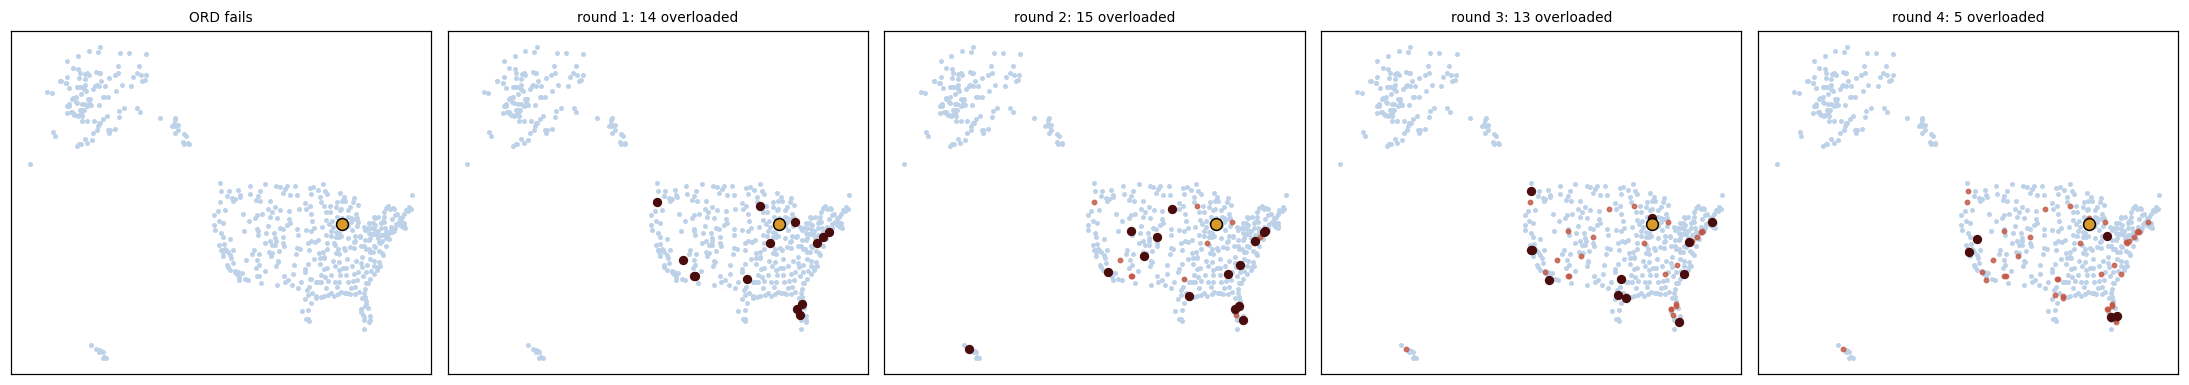

In [3]:
seed = LC.idx["ORD"]; alpha = 0.1
act = np.ones(N, dtype=bool); act[seed] = False
L1 = LC.loads(act); ratio = np.where(act & (LC.L0 > 0), L1 / LC.L0, 0)
first = pd.DataFrame({"airport": nodes, "load before": LC.L0 / 2, "load after ORD fails": L1 / 2, "ratio": ratio, "degree": [deg[n] for n in nodes]})
first = first[ratio > 1 + alpha].sort_values("ratio", ascending=False)
print(f"airports overloaded right after ORD is removed (load more than {1 + alpha:.1f} x normal): {len(first)}")
display(first.head(10).style.hide(axis="index").format({"load before": "{:.0f}", "load after ORD fails": "{:.0f}", "ratio": "{:.2f}"}))

res = LC.run("ORD", LC.capacity(alpha))
rows = []
for k, f in enumerate(res["failed_by_round"], start=1):
    rows.append({"round": k, "airports failing by overload": len(f), "examples": ", ".join(nodes[i] for i in f[:8])})
display(pd.DataFrame(rows).style.hide(axis="index"))
lcc0 = LC.lcc_size(act)
print(f"after ORD is removed: largest component {lcc0}; after {res['rounds']} cascade rounds ({res['n_overload']} airports overloaded): largest component {res['lcc']} of {N} ({res['lcc'] / N:.0%})")

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
state = np.zeros(N, dtype=int); state[seed] = 1                                      # 1 = origin, 2 = failed in earlier rounds, 3 = failing this round
for k in range(len(res["failed_by_round"]) + 1):
    ax = axes[k]
    if k > 0:
        state[state == 3] = 2; state[res["failed_by_round"][k - 1]] = 3
    xs = np.array([pos[n][0] for n in nodes]); ys = np.array([pos[n][1] for n in nodes])
    ax.scatter(xs[state == 0], ys[state == 0], s=5, color="#bdd2e8"); ax.scatter(xs[state == 2], ys[state == 2], s=8, color=RED, alpha=0.8)
    ax.scatter(xs[state == 3], ys[state == 3], s=26, color="#4a0d0d"); ax.scatter(xs[state == 1], ys[state == 1], s=60, color=ORANGE, edgecolor="black", zorder=5)
    ax.set_title("ORD fails" if k == 0 else f"round {k}: {len(res['failed_by_round'][k - 1])} overloaded", fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

**Reading this.** When ORD closes, its traffic flows to other airports and **14 airports are overloaded at once**, by 10 to 37% more than their normal load. They are a mix of big hubs with the largest absolute jumps (DTW, MSP, PHL, LAS, DFW) and *small airports* with the largest relative jumps (AZA +37%; PGD, PIE and SFB about +13 to 15%), which become shortcuts once ORD is gone. They fail, pushing their traffic onto the next tier (ATL, FLL, TPA, MCO, LAX, LGA in round 2; BOS, MIA, AUS, SAN, SEA in round 3). After only 4 rounds **47 airports have failed by overload**, and the loss of this backbone of mid-sized and large airports shatters the mainland network: the largest remaining component is just the Alaskan cluster (131 airports), because the hundreds of small airports have lost every hub they connected through.

This is a qualitatively different picture from the threshold cascade of M6: there, failure spreads from an airport to *its neighbours*; here it spreads to wherever the **traffic** goes.

### B2. How much spare capacity stops it?
We sweep alpha finely for six origins and record the final largest component. The dashed line is the damage done directly by removing the origin (disconnection), independent of capacity.

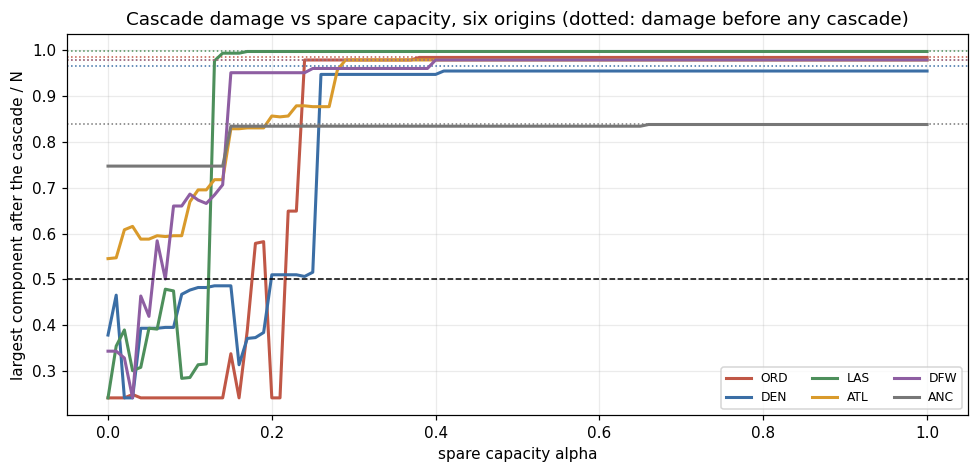

origin,largest component right after removal,alpha_c (largest alpha with a global cascade),alpha above which the overload damage stays under 2% of the airports
ORD,532,0.21,0.240000
DEN,522,0.19,0.260000
LAS,539,0.12,0.140000
ATL,529,none (no global cascade at any alpha),0.290000
DFW,529,0.05,0.250000
ANC,453,none (no global cascade at any alpha),0.150000


In [4]:
fine = np.round(np.arange(0, 1.0001, 0.01), 2)
sel = ["ORD", "DEN", "LAS", "ATL", "DFW", "ANC"]
M_, l0_ = LC.sweep(fine, seeds=[LC.idx[n] for n in sel])
cols = {"ORD": RED, "DEN": BLUE, "LAS": GREEN, "ATL": ORANGE, "DFW": PURPLE, "ANC": GREY}

fig, ax = plt.subplots(figsize=(9, 4.4))
for r, n in enumerate(sel):
    ax.plot(fine, M_[r] / N, color=cols[n], lw=2, label=n); ax.axhline(l0_[r] / N, color=cols[n], ls=":", lw=1)
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.set_xlabel("spare capacity alpha"); ax.set_ylabel("largest component after the cascade / N"); ax.set_title("Cascade damage vs spare capacity, six origins (dotted: damage before any cascade)"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for r, n in enumerate(sel):
    crit = fine[np.where(M_[r] <= N / 2)[0]]
    rows.append({"origin": n, "largest component right after removal": int(l0_[r]), "alpha_c (largest alpha with a global cascade)": f"{crit.max():.2f}" if len(crit) else "none (no global cascade at any alpha)",
                 "alpha above which the overload damage stays under 2% of the airports": float(fine[[all((l0_[r] - M_[r][j:]) <= 0.02 * N) for j in range(len(fine))].index(True)])})
pd.DataFrame(rows).style.hide(axis="index")

**Reading this.** The picture is a clear **threshold in the spare capacity**: below alpha_c the origin's failure destroys most of the network, and above it the cascade stops. The thresholds are small: ORD 0.21, DEN 0.19, LAS 0.12, DFW 0.05; **ATL never causes a global cascade at all** (even with no spare capacity its failure leaves 295 airports connected). ANC is different: its damage is **almost entirely direct**: removing it strands 87 Alaskan airports (453 airports left) whatever the capacity, because a gateway's failure is a connectivity failure, not an overload failure. Only at the very lowest capacities does overload add a little more (the largest component falls to about 400); from alpha of about 0.3 the cascade adds almost nothing (451 to 453 left). Capacity cannot protect against the direct loss; redundancy (more routes) is needed.

## Part C. Every airport as the origin: the phase diagram
We now run the cascade from each of the 541 airports, for alpha from 0 to 1 in steps of 0.05. An origin causes a **global cascade** if the final largest component is at most half of the airports.

In [5]:
alphas = np.round(np.arange(0, 1.0001, 0.05), 3)
t0 = time.time()
R, lcc0 = LC.sweep(alphas)
print(f"all-origin sweep: {N} origins x {len(alphas)} values of alpha in {time.time() - t0:.0f} s")

glob = (R <= N / 2)
p_glob = glob.mean(0)
alpha_c = np.array([alphas[np.where(glob[i])[0]].max() if glob[i].any() else -1.0 for i in range(N)])
a_star = alpha_c.max()
over_dmg = (lcc0[:, None] - R) / N                          # damage beyond the direct disconnection, as a share of N
safe_candidates = [a for gi, a in enumerate(alphas) if over_dmg[:, gi:].max() <= 0.05]
alpha_safe = safe_candidates[0] if safe_candidates else None

summary = pd.DataFrame({"spare capacity alpha": [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50, 1.0]})
ix = [list(alphas).index(a) for a in summary.alpha if a in alphas] if False else [int(np.argmin(abs(alphas - a))) for a in summary["spare capacity alpha"]]
summary["origins causing a global cascade"] = [f"{int(glob[:, i].sum())}  ({p_glob[i]:.1%})" for i in ix]
summary["mean final largest component / N"] = [round(R[:, i].mean() / N, 3) for i in ix]
summary["worst origin: final largest component"] = [f"{R[:, i].min()} ({nodes[int(R[:, i].argmin())]})" for i in ix]
display(summary.style.hide(axis="index"))
print(f"network-level critical tolerance alpha* (above it no single failure causes a global cascade): {a_star:.2f}, set by {nodes[int(alpha_c.argmax())]}")
print(f"spare capacity needed to keep the overload-driven extra damage of every single failure below 5% of the airports: alpha = {alpha_safe}")
print(f"origins that can cause a global cascade at some alpha on the grid: {(alpha_c >= 0).sum()}")

all-origin sweep: 541 origins x 21 values of alpha in 27 s


spare capacity alpha,origins causing a global cascade,mean final largest component / N,worst origin: final largest component
0.000000,40 (7.4%),0.922000,112 (MEM)
0.050000,10 (1.8%),0.980000,131 (ORD)
0.100000,5 (0.9%),0.987000,131 (ORD)
0.150000,2 (0.4%),0.993000,183 (ORD)
0.200000,1 (0.2%),0.994000,131 (ORD)
0.250000,0 (0.0%),0.996000,279 (DEN)
0.300000,0 (0.0%),0.997000,451 (ANC)
0.500000,0 (0.0%),0.997000,451 (ANC)
1.000000,0 (0.0%),0.997000,453 (ANC)


network-level critical tolerance alpha* (above it no single failure causes a global cascade): 0.20, set by ORD
spare capacity needed to keep the overload-driven extra damage of every single failure below 5% of the airports: alpha = 0.3
origins that can cause a global cascade at some alpha on the grid: 41


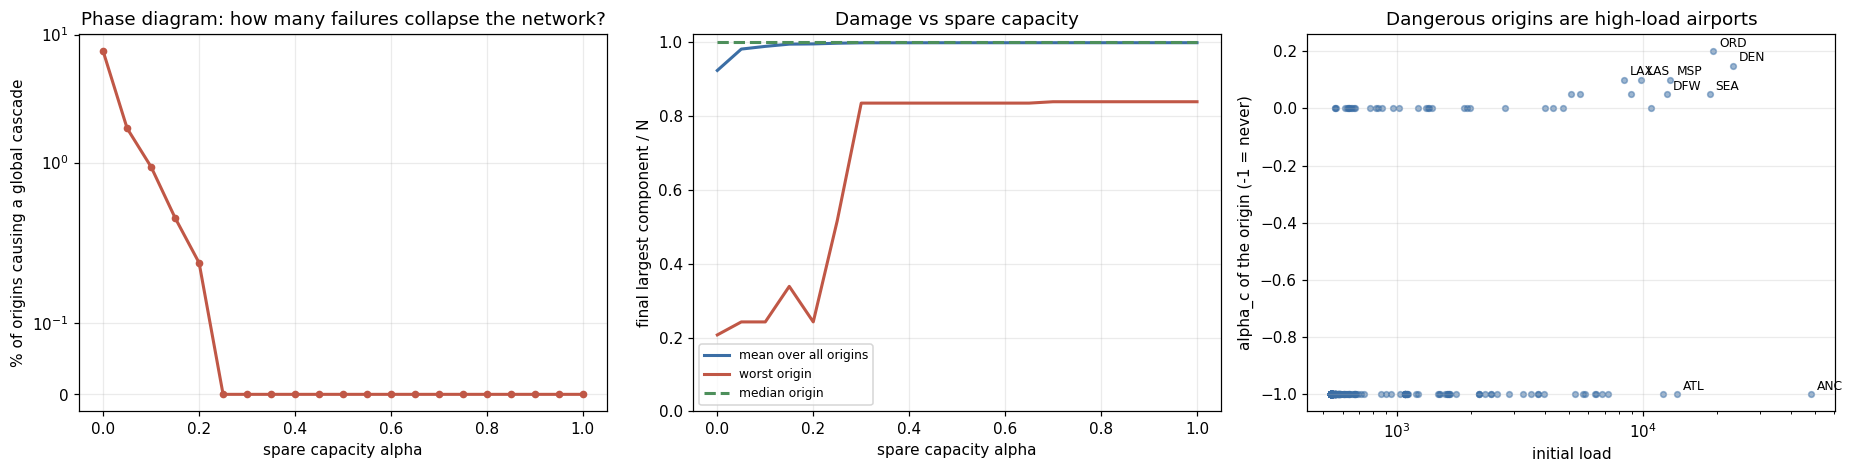

In [6]:
deg_arr = np.array([deg[n] for n in nodes])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]; ax.plot(alphas, 100 * p_glob, "o-", color=RED, lw=2, ms=4); ax.set_xlabel("spare capacity alpha"); ax.set_ylabel("% of origins causing a global cascade"); ax.set_title("Phase diagram: how many failures collapse the network?")
ax.set_yscale("symlog", linthresh=0.2)
ax = axes[1]; ax.plot(alphas, R.mean(0) / N, color=BLUE, lw=2, label="mean over all origins"); ax.plot(alphas, R.min(0) / N, color=RED, lw=2, label="worst origin"); ax.plot(alphas, np.median(R, 0) / N, color=GREEN, lw=2, ls="--", label="median origin")
ax.set_xlabel("spare capacity alpha"); ax.set_ylabel("final largest component / N"); ax.set_title("Damage vs spare capacity"); ax.legend(fontsize=8); ax.set_ylim(0, 1.02)
ax = axes[2]; ax.scatter(load.values, alpha_c, s=14, alpha=0.5, color=BLUE)
for n in ["ORD", "DEN", "LAS", "MSP", "LAX", "ATL", "ANC", "SEA", "DFW"]: ax.annotate(n, (load[n], alpha_c[LC.idx[n]]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("initial load"); ax.set_ylabel("alpha_c of the origin (-1 = never)"); ax.set_title("Dangerous origins are high-load airports")
plt.tight_layout(); plt.show()

In [7]:
bc_s = pd.Series(bc); load_rank = load.rank(ascending=False, method="min")
tab = pd.DataFrame({"origin": nodes, "city": [G.nodes[n]["city"] for n in nodes], "alpha_c": alpha_c, "degree": deg_arr, "load rank": load_rank.values.astype(int),
                    "cascade at alpha = 0.05": R[:, int(np.argmin(abs(alphas - 0.05)))], "cascade at alpha = 0.10": R[:, int(np.argmin(abs(alphas - 0.10)))], "direct damage (largest component after removal)": lcc0})
display(tab.sort_values(["alpha_c", "cascade at alpha = 0.10"], ascending=[False, True]).head(12).style.hide(axis="index"))

origin,city,alpha_c,degree,load rank,cascade at alpha = 0.05,cascade at alpha = 0.10,direct damage (largest component after removal)
ORD,Chicago,0.200000,149,3,131,131,532
DEN,Denver,0.150000,149,2,213,258,522
LAS,Las Vegas,0.100000,113,10,213,155,539
MSP,Minneapolis,0.100000,117,6,140,204,533
LAX,Los Angeles,0.100000,85,12,261,269,535
SEA,Seattle,0.050000,75,4,259,346,537
DFW,Dallas-Fort Worth,0.050000,138,7,227,371,529
IAH,Houston,0.050000,101,21,198,371,538
SLC,Salt Lake City,0.050000,85,11,224,533,533
PHX,Phoenix,0.050000,77,19,253,537,539


**Reading this.**
- **Remarkably little spare capacity is enough.** Without any spare capacity (alpha = 0) about 40 airports can each collapse the network; with 5% spare capacity 10 airports can; with 10% only 5; with 20% a single one (ORD); **from alpha = 0.25 or so no single airport failure causes a global cascade**. The network-level critical tolerance is about 0.2, and keeping the *extra* damage that overload adds to any single failure below 5% of the airports needs alpha of about 0.3. (We did not test why the margin needed is so small; it is consistent with a small group of very high-load airports whose traffic the many mid-sized airports can absorb.)
- **The dangerous origins are high-load hubs**: ORD, DEN, LAS, MSP, LAX, then SEA, IAH, SLC, DFW, PHX. Note that **ATL is not among the most dangerous** here, and neither are PIE or SFB, the small airports that were dangerous in M6.
- **What remains at high alpha is not a cascade:** the worst origin at alpha = 1 is ANC with a final largest component of 453, which is the direct damage of cutting Alaska off. Spare capacity cannot fix that; extra routes can.

## Part D. Are the same airports dangerous in the threshold model and in the load model?
M6 found that the most dangerous origins in the threshold cascade were LAS, MSP, DFW (then PIE, SFB, ATL), and that ORD could not collapse the network at all. We compute the same quantity (each origin's own critical threshold t_c) and compare it with alpha_c.

Spearman correlation of an origin's danger between the two models: alpha_c (load model) vs t_c (threshold model) = 0.38
   load model danger vs initial load 0.43, vs degree 0.39;   threshold model danger vs degree 0.49
overlap of the top-10 most dangerous origins: 6 airports in common: ['DEN', 'DFW', 'IAH', 'LAS', 'MSP', 'ORD']


origin,load model: alpha_c,load model: rank,threshold model: t_c,threshold model: rank
ORD,0.20,1,0.140,10
DEN,0.15,2,0.150,9
LAS,0.10,3,0.200,1
MSP,0.10,3,0.185,2
LAX,0.10,3,0.110,21
DFW,0.05,6,0.175,3
ATL,none,42,0.165,4
PIE,none,42,0.165,4
SFB,none,42,0.165,4
ANC,none,42,0.050,90


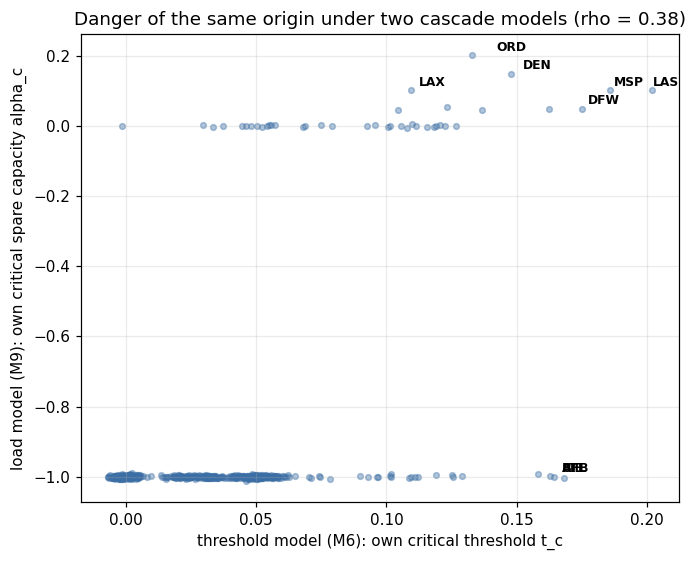

In [8]:
Cc = cs.Cascade(G); tgrid = np.round(np.arange(0.02, 0.4001, 0.005), 3)
t_c = np.array([max([t for t in tgrid if Cc.run([i], Cc.need(t))[0].sum() >= 0.5 * N] or [0.0]) for i in range(N)])

rho_tc = spearmanr(alpha_c, t_c).statistic; rho_deg_load = spearmanr(alpha_c, deg_arr).statistic; rho_load = spearmanr(alpha_c, load.values).statistic; rho_deg_t = spearmanr(t_c, deg_arr).statistic
ranks = lambda a: pd.Series(a, index=nodes).rank(ascending=False, method="min")
top_l = set(pd.Series(alpha_c, index=nodes).sort_values(ascending=False).head(10).index); top_t = set(pd.Series(t_c, index=nodes).sort_values(ascending=False).head(10).index)
print(f"Spearman correlation of an origin's danger between the two models: alpha_c (load model) vs t_c (threshold model) = {rho_tc:.2f}")
print(f"   load model danger vs initial load {rho_load:.2f}, vs degree {rho_deg_load:.2f};   threshold model danger vs degree {rho_deg_t:.2f}")
print(f"overlap of the top-10 most dangerous origins: {len(top_l & top_t)} airports in common: {sorted(top_l & top_t)}")

cmp = pd.DataFrame({"origin": ["ORD", "DEN", "LAS", "MSP", "LAX", "DFW", "ATL", "PIE", "SFB", "ANC"]})
cmp["load model: alpha_c"] = [f"{alpha_c[LC.idx[n]]:.2f}" if alpha_c[LC.idx[n]] >= 0 else "none" for n in cmp.origin]; cmp["load model: rank"] = [int(ranks(alpha_c)[n]) for n in cmp.origin]
cmp["threshold model: t_c"] = [f"{t_c[LC.idx[n]]:.3f}" for n in cmp.origin]; cmp["threshold model: rank"] = [int(ranks(t_c)[n]) for n in cmp.origin]
display(cmp.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(6.4, 5.2))
jit = lambda v: v + rng.normal(0, 0.003, len(v))
ax.scatter(jit(t_c), jit(alpha_c), s=14, alpha=0.4, color=BLUE)
for n in ["ORD", "DEN", "LAS", "MSP", "LAX", "DFW", "ATL", "PIE", "SFB"]: ax.annotate(n, (t_c[LC.idx[n]], alpha_c[LC.idx[n]]), xytext=(4, 3), textcoords="offset points", fontsize=8, weight="bold")
ax.set_xlabel("threshold model (M6): own critical threshold t_c"); ax.set_ylabel("load model (M9): own critical spare capacity alpha_c"); ax.set_title(f"Danger of the same origin under two cascade models (rho = {rho_tc:.2f})")
plt.tight_layout(); plt.show()

**Reading this.** The two models agree only partly (Spearman 0.38), but not on nothing: **six of the ten most dangerous origins are the same** (ORD, DEN, LAS, MSP, DFW, IAH), though in a different order.
- **The biggest disagreements:** ORD is the *most* dangerous origin in the load model but ranks tenth, the lowest of the big hubs, in the threshold model (where it could not even collapse the network at threshold 0.15); LAS, which is first in the threshold model, is third here. **ATL, PIE and SFB are dangerous only in the threshold model** (never in the load model); DFW is dangerous in both, much more so in the threshold model.
- The reason is the different mechanism. In the threshold model what matters is how many of an airport's neighbours are **small and easily tipped** (ATL has 42 such neighbours). In the load model what matters is **how much traffic an airport carries that other airports must absorb**: ORD, DEN and LAS sit in the middle of many shortest paths. A hub can be a catastrophic threshold-model origin without carrying much through-traffic, and a through-traffic hub need not have many fragile neighbours.
- Both models agree that the dangerous airports are a **small, specific set**, so a protection plan has to be designed from the cascade model one believes. The paper's single threshold-model conclusion ("if a major hub such as ATL, ORD or DFW fails the network can collapse") is model-dependent: in the load model ATL does not, ORD does most.

## Part E. How much do the answers depend on modelling choices?
Five variants. For each we repeat the all-origin sweep.
1. **Baseline:** unit traffic between every pair of airports; load includes the airport's own traffic; capacity (1 + alpha) x load.
2. **Transit only** (the textbook Motter-Lai definition): only traffic *passing through* an airport counts as load. Airports that carry no through-traffic initially are never overloaded.
3. **Gravity traffic:** an airport generates and attracts traffic in proportion to its size (strength), so big airports exchange most traffic.
4. **Additive spare capacity:** every airport gets the same *absolute* spare capacity (alpha times the mean load) instead of a proportional one, which protects small airports and penalises hubs.
5. **Heterogeneous tolerance:** each airport's alpha is multiplied by a random factor between 0 and 2 (mean 1), so some airports have almost no spare capacity.

The meaning of alpha differs a little between variants (it is always the average spare capacity), so we compare the *shape* of the transition and the ranking of origins.

In [9]:
LC_T = lc.LoadCascade(G, endpoints=False)
LC_G = lc.LoadCascade(G, demand=strength)
variants = {}
t0 = time.time()
variants["baseline"] = (R, alpha_c)
def run_variant(name, eng, cap_fn=None):
    Rv, _ = eng.sweep(alphas, cap_fn=cap_fn)
    gl = (Rv <= N / 2); ac = np.array([alphas[np.where(gl[i])[0]].max() if gl[i].any() else -1.0 for i in range(N)])
    variants[name] = (Rv, ac)
run_variant("transit-only load", LC_T)
run_variant("gravity traffic", LC_G)
run_variant("additive spare capacity", LC, lambda a: LC.capacity_additive(a))
u1 = rng.uniform(0, 2, N); u2 = rng.uniform(0, 2, N)
run_variant("heterogeneous tolerance (draw 1)", LC, lambda a: LC.capacity_het(a, u1))
run_variant("heterogeneous tolerance (draw 2)", LC, lambda a: LC.capacity_het(a, u2))
print(f"variants computed in {time.time() - t0:.0f} s")

rows = []
for name, (Rv, ac) in variants.items():
    gl = (Rv <= N / 2); top3 = pd.Series(ac, index=nodes).sort_values(ascending=False).head(3)
    rows.append({"variant": name, "alpha*": ac.max(), "origins causing a global cascade at alpha = 0": int(gl[:, 0].sum()), "... at alpha = 0.1": int(gl[:, int(np.argmin(abs(alphas - 0.1)))].sum()),
                 "most dangerous origins": ", ".join(f"{n} ({v:.2f})" for n, v in top3.items()),
                 "rank correlation of alpha_c with baseline": spearmanr(ac, alpha_c).statistic, "... with threshold model t_c": spearmanr(ac, t_c).statistic})
vt = pd.DataFrame(rows); vt.style.hide(axis="index").format({"alpha*": "{:.2f}", "rank correlation of alpha_c with baseline": "{:.2f}", "... with threshold model t_c": "{:.2f}"})

variants computed in 191 s


variant,alpha*,origins causing a global cascade at alpha = 0,... at alpha = 0.1,most dangerous origins,rank correlation of alpha_c with baseline,... with threshold model t_c
baseline,0.20,40,5,"ORD (0.20), DEN (0.15), LAS (0.10)",1.00,0.38
transit-only load,0.25,15,3,"DEN (0.25), MSP (0.15), SEA (0.15)",0.60,0.27
gravity traffic,0.05,6,0,"ORD (0.05), SLC (0.00), MSP (0.00)",0.39,0.19
additive spare capacity,1.00,40,23,"CLT (1.00), DEN (1.00), SLC (1.00)",0.88,0.45
heterogeneous tolerance (draw 1),0.35,40,5,"SEA (0.35), DEN (0.25), PDX (0.20)",0.97,0.38
heterogeneous tolerance (draw 2),0.25,40,8,"ORD (0.25), DEN (0.20), MSP (0.20)",1.00,0.38


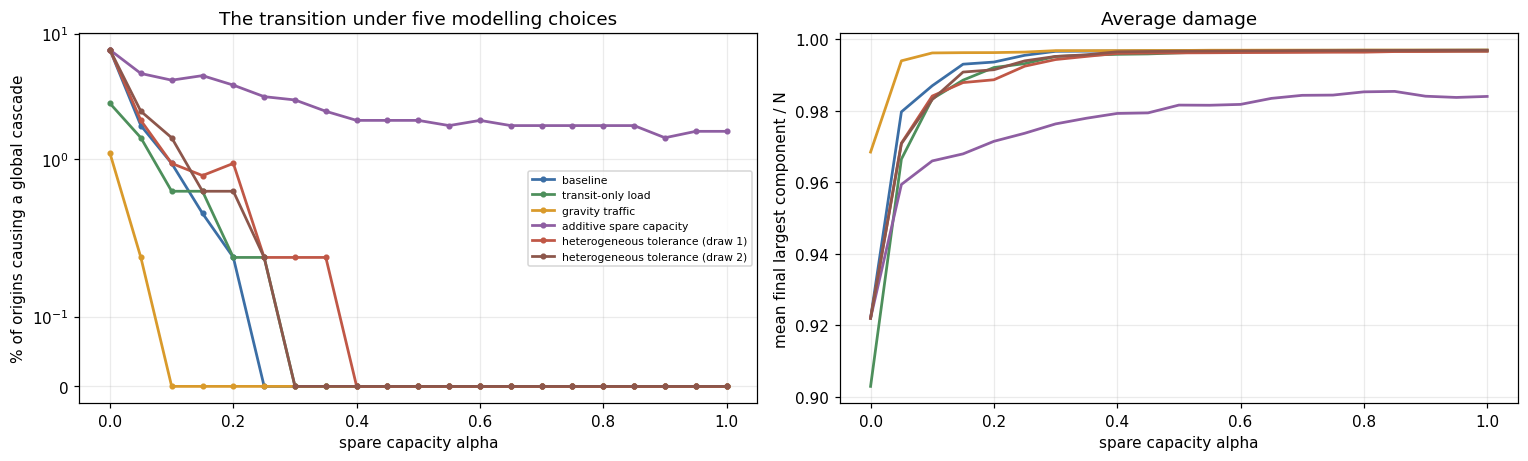

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
vc = {"baseline": BLUE, "transit-only load": GREEN, "gravity traffic": ORANGE, "additive spare capacity": PURPLE, "heterogeneous tolerance (draw 1)": RED, "heterogeneous tolerance (draw 2)": BROWN}
for name, (Rv, ac) in variants.items():
    axes[0].plot(alphas, 100 * (Rv <= N / 2).mean(0), "o-", ms=3, color=vc[name], label=name, lw=1.8)
axes[0].set_yscale("symlog", linthresh=0.2); axes[0].set_xlabel("spare capacity alpha"); axes[0].set_ylabel("% of origins causing a global cascade"); axes[0].set_title("The transition under five modelling choices"); axes[0].legend(fontsize=7)
for name, (Rv, ac) in variants.items(): axes[1].plot(alphas, Rv.mean(0) / N, color=vc[name], lw=1.8, label=name)
axes[1].set_xlabel("spare capacity alpha"); axes[1].set_ylabel("mean final largest component / N"); axes[1].set_title("Average damage")
plt.tight_layout(); plt.show()

**Reading this.** The *qualitative* result survives every variant: there is a threshold in the spare capacity, the origins that can cause a global cascade are few, and they become fewer as capacity grows. The *quantitative* answers depend strongly on the modelling choices (see the table):
- **Transit-only load** (the textbook definition): fewer origins can cause a global cascade at alpha = 0 (15 instead of 40), but the critical tolerance is a little higher (0.25) and the dangerous set changes (DEN, MSP, SEA).
- **Gravity traffic** (traffic proportional to airport size) makes the network **much safer**: critical tolerance 0.05 and only 6 origins dangerous at alpha = 0. When most traffic flows between big airports, which are densely interconnected, a hub failure re-routes it with little extra load.
- **Additive spare capacity** (the same absolute margin for every airport) is **far worse**: the critical tolerance is at the edge of the grid (1.0 or more) and 23 origins are dangerous at alpha = 0.1 (against 5), because the hubs, which carry most of the load, then have only a tiny *relative* margin. Proportional allocation is much better at the same average margin.
- **Heterogeneous tolerance** raises the critical tolerance a little (0.25 and 0.35 for the two random draws) and changes who is most dangerous (SEA or ORD), so the exact numbers and the list of dangerous airports depend on which airports happen to have little spare capacity.

The consistent message for planning: **spare capacity should scale with load** (proportional, or higher at high-load airports), not be uniform in absolute terms; M11 tests targeted reinforcement directly.

## Part F. Robustness on the operated-only network
As in M7, we repeat the baseline analysis on the network without codeshare-only edges (446 airports) and compare with the paper network on the airports they share.

In [11]:
LC_op = lc.LoadCascade(Gop); Nop = LC_op.n
Rop, lcc0_op = LC_op.sweep(alphas)
gl_op = (Rop <= Nop / 2); ac_op = np.array([alphas[np.where(gl_op[i])[0]].max() if gl_op[i].any() else -1.0 for i in range(Nop)])
common = [n for n in LC_op.nodes if n in LC.idx]
a1 = np.array([alpha_c[LC.idx[n]] for n in common]); a2 = np.array([ac_op[LC_op.idx[n]] for n in common])
print(f"operated-only network ({Nop} airports): network-level critical tolerance alpha* = {ac_op.max():.2f}; origins causing a global cascade at alpha = 0: {int(gl_op[:, 0].sum())}, at 0.1: {int(gl_op[:, int(np.argmin(abs(alphas - 0.1)))].sum())}")
print("most dangerous origins:", ", ".join(f"{n} ({v:.2f})" for n, v in pd.Series(ac_op, index=LC_op.nodes).sort_values(ascending=False).head(6).items()))
print(f"rank correlation of alpha_c between the two networks, {len(common)} common airports: {spearmanr(a1, a2).statistic:.2f}")
print(f"paper network: alpha* = {a_star:.2f}; most dangerous: " + ", ".join(f"{n} ({v:.2f})" for n, v in pd.Series(alpha_c, index=nodes).sort_values(ascending=False).head(6).items()))

operated-only network (446 airports): network-level critical tolerance alpha* = 0.30; origins causing a global cascade at alpha = 0: 38, at 0.1: 3
most dangerous origins: DEN (0.30), LAS (0.15), ORD (0.10), PHX (0.05), MSP (0.05), LAX (0.05)
rank correlation of alpha_c between the two networks, 446 common airports: 0.75
paper network: alpha* = 0.20; most dangerous: ORD (0.20), DEN (0.15), LAS (0.10), LAX (0.10), MSP (0.10), SLC (0.05)


**Reading this.** The operated-only network gives the same qualitative picture: a sharp threshold in spare capacity, a small dangerous set (38 origins at alpha = 0, 3 at alpha = 0.1) and a similarly small critical tolerance (0.30 against 0.20). The three most dangerous origins are the same airports as on the paper network (DEN, LAS, ORD, in a different order), and the ranking of origins is strongly related across the two networks (Spearman 0.75). The *exact* thresholds and order are therefore somewhat sensitive to the data version, as in M6 and M7; the existence of a small dangerous set and of a low critical tolerance is not.

## Part G. Which airports overload? A preview for protection (M11)
If spare capacity is to be added where it matters, we need to know which airports fail by overload. For each alpha in (0.05, 0.10, 0.20) we run every origin that triggers an overload and count how often each airport fails.

In [12]:
fail_count = {a: Counter() for a in (0.05, 0.10, 0.20)}
n_active = {a: 0 for a in fail_count}
for a in fail_count:
    cap = LC.capacity(a)
    for s in range(N):
        act = np.ones(N, dtype=bool); act[s] = False
        L1 = LC.loads(act)
        if (act & (L1 > cap * (1 + 1e-9) + 1e-9)).any():
            r = LC.run(s, cap); n_active[a] += 1
            for f in r["failed_by_round"]: fail_count[a].update(nodes[i] for i in f)

rows = []
for a, cnt in fail_count.items():
    tot = sum(cnt.values()); top10 = cnt.most_common(10)
    rows.append({"alpha": a, "origins that trigger any overload": n_active[a], "airports that ever fail by overload": len(cnt),
                 "share of all overload failures at the 10 most frequent airports": f"{sum(v for _, v in top10) / tot:.0%}" if tot else "-",
                 "most frequently overloaded": ", ".join(f"{n} ({v})" for n, v in top10[:6])})
pd.DataFrame(rows).style.hide(axis="index")

alpha,origins that trigger any overload,airports that ever fail by overload,share of all overload failures at the 10 most frequent airports,most frequently overloaded
0.050000,49,132,21%,"PGD (23), PIE (22), SFB (21), TPA (17), AZA (17), MDW (17)"
0.100000,39,120,23%,"PIE (16), SFB (15), PGD (13), MIA (12), TPA (10), ORD (10)"
0.200000,30,88,26%,"PIE (7), SFB (6), PGD (5), MYR (5), AZA (3), DCA (3)"


**Reading this.** Overload failures are **not** concentrated on the hubs, and they are not confined to a handful of airports: at alpha = 0.10 about 120 airports (22% of the network) fail by overload in at least one cascade, and the ten most frequent account for only about a quarter of all overload failures. The airports that fail most often are **small and mid-sized leisure airports** (Punta Gorda PGD, St. Petersburg-Clearwater PIE, Sanford SFB, Phoenix-Mesa Gateway AZA, Myrtle Beach MYR) together with a few big airports (TPA, MIA, MDW, ORD): they have small initial loads, so any traffic re-routed through them quickly exceeds their capacity. (PIE and SFB are the same airports that were dangerous *origins* in the threshold model of M6: here they are the most frequent *victims*.) This matters for protection: reinforcing only the high-load hubs will not remove overload risk at the small airports where re-routed traffic lands, which M11 tests.

## Part H. Verdict

In [13]:
verdict = pd.DataFrame([
    ("(paper) the cascade is a neighbour-threshold model (M6)",
     "A topological model with no traffic, capacity or rerouting. The load model is the standard physical alternative and its results are quite different for individual airports", "gap addressed"),
    ("Spare capacity needed for safety",
     f"About {a_star:.2f}: from alpha = 0.25 no single airport failure causes a global cascade (baseline model, unit traffic); only {int(glob[:, 0].sum())} origins can at alpha = 0", "new finding"),
    ("Which airports are dangerous",
     f"High-load hubs: {', '.join(pd.Series(alpha_c, index=nodes).sort_values(ascending=False).head(5).index)}; ATL, PIE and SFB (dangerous in M6) are not", "new finding"),
    ("Same airports in both cascade models?",
     f"Only partly (Spearman {rho_tc:.2f}); ORD is the most dangerous here and the least dangerous major hub in M6; hence the paper's 'if ATL, ORD or DFW fails the network collapses' is model-dependent", "model-dependent"),
    ("Capacity cannot protect against gateway failures",
     f"ANC's damage is almost entirely direct (largest component {lcc0[LC.idx['ANC']]} of {N} right after removal; {R[LC.idx['ANC']].min()} at worst): extra routes, not extra capacity, are needed for Alaska", "new finding"),
    ("Sensitivity to modelling choices",
     "The existence of a threshold in spare capacity and the small dangerous set are robust across five variants and on the operated-only network; the exact alpha*, and the list of dangerous airports, are not", "qualitatively robust"),
    ("Where capacity matters",
     f"About {len(fail_count[0.10])} airports ({len(fail_count[0.10]) / N:.0%}) fail by overload in some cascade at alpha = 0.10; the most frequent victims are small leisure airports (PGD, PIE, SFB, AZA), not the hubs: protection must consider where traffic lands, not only the high-load airports (M11)", "sets up M11"),
], columns=["question", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["question", "what we find"], **{"text-align": "left", "white-space": "normal"})

question,what we find,status
(paper) the cascade is a neighbour-threshold model (M6),"A topological model with no traffic, capacity or rerouting. The load model is the standard physical alternative and its results are quite different for individual airports",gap addressed
Spare capacity needed for safety,"About 0.20: from alpha = 0.25 no single airport failure causes a global cascade (baseline model, unit traffic); only 40 origins can at alpha = 0",new finding
Which airports are dangerous,"High-load hubs: ORD, DEN, LAS, LAX, MSP; ATL, PIE and SFB (dangerous in M6) are not",new finding
Same airports in both cascade models?,"Only partly (Spearman 0.38); ORD is the most dangerous here and the least dangerous major hub in M6; hence the paper's 'if ATL, ORD or DFW fails the network collapses' is model-dependent",model-dependent
Capacity cannot protect against gateway failures,"ANC's damage is almost entirely direct (largest component 453 of 541 right after removal; 404 at worst): extra routes, not extra capacity, are needed for Alaska",new finding
Sensitivity to modelling choices,"The existence of a threshold in spare capacity and the small dangerous set are robust across five variants and on the operated-only network; the exact alpha*, and the list of dangerous airports, are not",qualitatively robust
Where capacity matters,"About 120 airports (22%) fail by overload in some cascade at alpha = 0.10; the most frequent victims are small leisure airports (PGD, PIE, SFB, AZA), not the hubs: protection must consider where traffic lands, not only the high-load airports (M11)",sets up M11


## Checks

In [14]:
iA = LC.idx["ANC"]; iO = LC.idx["ORD"]; iT = LC.idx["ATL"]
act_ord = np.ones(N, dtype=bool); act_ord[iO] = False
ci = int(np.argmin(abs(alphas - 0.3)))
checks = [
    ("loads match networkx and brute force", diff_nx < 1e-6 and diff_brute < 1e-6),
    ("ANC has the highest load; load ranking = betweenness ranking", load.idxmax() == "ANC" and list(bc_rank.sort_values().index[:3]) == ["ANC", "DEN", "ORD"]),
    ("smallest load = N - 1", abs(load.min() - (N - 1)) < 1e-6),
    ("ORD at alpha 0.1: 47 overload failures, 4 rounds, final component 131", res["n_overload"] == 47 and res["rounds"] == 4 and res["lcc"] == 131),
    ("removing ORD leaves a component of 532", LC.lcc_size(act_ord) == 532),
    ("ANC damage is almost purely direct (453 airports left directly; at least 400 for any alpha; 451+ from alpha 0.3)", lcc0[iA] == 453 and R[iA].min() >= 400 and (R[iA, ci:] >= 451).all()),
    ("many origins cause a global cascade at alpha 0", glob[:, 0].sum() > 20),
    ("no origin causes a global cascade from alpha 0.3", glob[:, ci:].sum() == 0),
    ("ORD sets alpha*", a_star == alpha_c[iO] and nodes[int(alpha_c.argmax())] == "ORD"),
    ("fewer dangerous origins as capacity grows", bool(np.all(np.diff(p_glob) <= 1e-12))),
    ("ATL less dangerous than ORD in the load model, more in the threshold model", alpha_c[iT] < alpha_c[iO] and t_c[iO] < t_c[iT]),
    ("models partly agree (0.2 < rho < 0.6)", 0.2 < rho_tc < 0.6),
    ("every variant has a global cascade somewhere and alpha_c within the grid", all(v[1].max() <= 1.0 and (v[0] <= N / 2).sum() > 0 for v in variants.values())),
    ("operated-only ranking positively related", spearmanr(a1, a2).statistic > 0.3),
    ("overload failures concentrated on few airports", len(fail_count[0.10]) < N / 4 and n_active[0.05] > n_active[0.10] > n_active[0.20]),
]
failed = [lab for lab, ok in checks if not ok]
print(f"{len(checks) - len(failed)} of {len(checks)} checks passed")
assert not failed, failed
print("All M9 assertions passed.")

15 of 15 checks passed
All M9 assertions passed.


## Summary and take-aways

- **A physically motivated cascade model.** In the Motter-Lai load-capacity model an airport carries all the shortest-path traffic through it (with unit traffic this is the paper's betweenness plus N - 1) and fails when it carries more than (1 + alpha) times its original load. We implemented and validated it (against networkx and brute force), with traffic weights and compiled code fast enough to run the cascade from every airport.
- **Very little spare capacity suffices.** About 40 airports can each collapse the network with no spare capacity, 10 with 5%, 5 with 10%, 1 (ORD) with 20%, and **none from about 25%**: the network-level critical tolerance is about 0.2. The remaining damage after that is direct (cutting off Alaska through ANC), which spare capacity cannot fix.
- **Dangerous airports are high-load hubs: ORD, DEN, LAS, MSP, LAX**; ATL and the small leisure airports PIE and SFB, dangerous in the threshold model, are never dangerous here, and DFW much less. The two cascade models agree only partly (Spearman 0.38; 6 of the top 10 origins in common): the paper's single conclusion that a failing ATL, ORD or DFW can collapse the network is **model-dependent**.
- **The cascade spreads along traffic, not along links:** ORD's failure overloads 14 airports at once (big hubs and small shortcut airports), then the next tier, and 47 airports fail in 4 rounds, destroying the backbone and leaving only the Alaskan cluster connected. About 0.3 spare capacity keeps the overload damage of any single failure below 5% of the airports.
- **Robustness:** a threshold in the spare capacity and a small dangerous set appear under all five model variants and on the operated-only network; the exact critical tolerance (from 0.05 with gravity traffic to at least 1 with additive capacity) and the list of dangerous airports depend strongly on the modelling choices and somewhat on the data version.
- **For protection (M11):** capacity should scale with load (the uniform additive rule is much worse); and overload failures land mostly on small and mid-sized leisure airports (about 120 airports at alpha = 0.10), so reinforcing only the highest-load hubs will not remove overload risk. M11 tests this.
- **Caveats:** shortest-path routing with equal traffic (or size-proportional traffic) is a stylised description of passenger flows; capacity is the only constraint (no schedules, no delay, no airline structure); results describe the 2014 OpenFlights topology.

**Next:** M10 repeats the main analysis for other countries, India first.